In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
import warnings 
warnings.filterwarnings('ignore')

In [4]:
df= pd.read_csv('spotify_new_dataset.csv')

In [5]:
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [6]:
df.columns

Index(['track_id', 'artists', 'album_name', 'track_name', 'popularity',
       'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness',
       'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'time_signature', 'track_genre'],
      dtype='object')

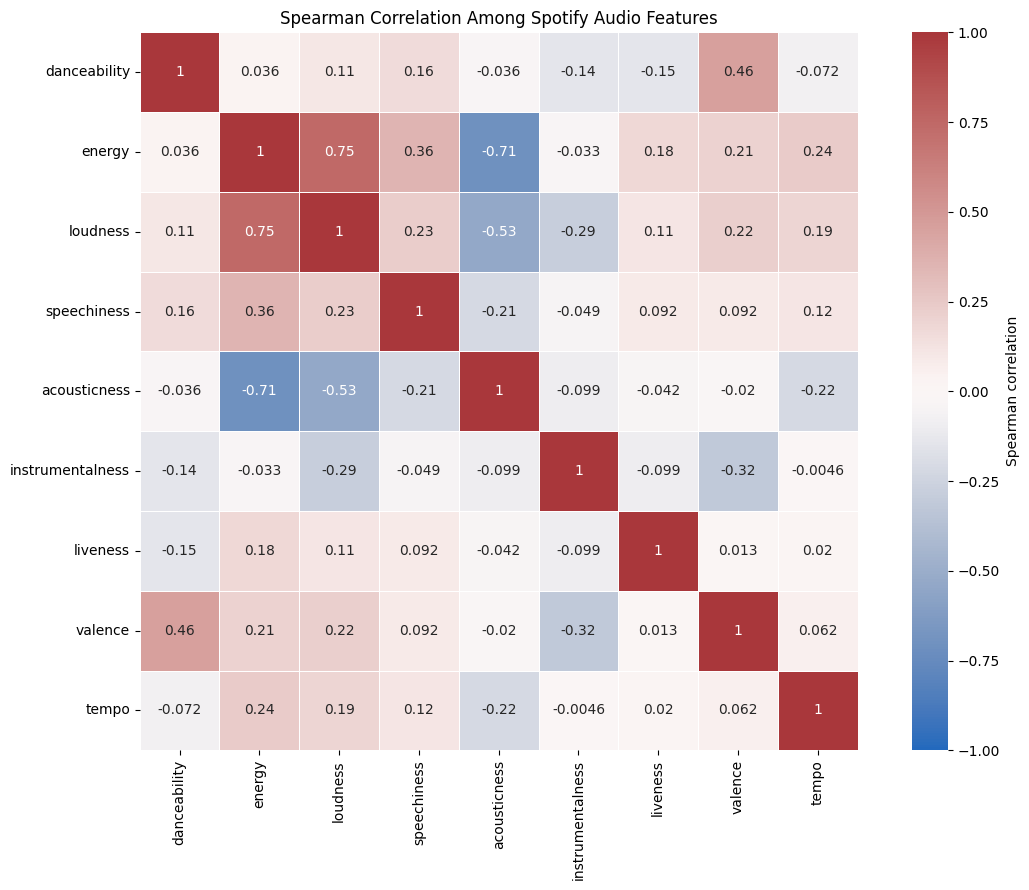

In [7]:
audio_features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

correlation_features = [column for column in audio_features if column in df.columns]
spearman_correlation = df[correlation_features].corr(method='spearman')

plt.figure(figsize=(12, 9))
sns.heatmap(
    spearman_correlation, cmap='vlag', vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.4, cbar_kws={'label': 'Spearman correlation'}, annot=True
)
plt.title('Spearman Correlation Among Spotify Audio Features')
plt.tight_layout()
plt.show()


In [9]:
df['explicit'].value_counts()

explicit
False    103831
True       9718
Name: count, dtype: int64

In [10]:
df['key'].value_counts()

key
7     13199
0     13006
2     11594
9     11264
1     10740
5      9325
11     9251
4      8971
6      7891
10     7423
8      7337
3      3548
Name: count, dtype: int64

In [11]:
df['mode'].value_counts()

mode
1    72429
0    41120
Name: count, dtype: int64

In [12]:
metadata_df = df[
    [
        'track_id',
        'track_name',
        'artists',
        'album_name',
        'track_genre',
        'key',
        'mode',
        'explicit'
    ]
].copy()

In [14]:
metadata_df.to_csv('metadata.csv',index=False)

In [16]:
df.drop(['track_id', 'track_name', 'artists', 'album_name', 'track_genre','key','mode','explicit'],axis=1,inplace=True)

In [17]:
df.columns

Index(['popularity', 'duration_ms', 'danceability', 'energy', 'loudness',
       'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'time_signature'],
      dtype='object')

In [18]:
    df.head()

,popularity,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,73,230666,0.676,0.4610,-6.746,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4
1,55,149610,0.420,0.1660,-17.235,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4
2,57,210826,0.438,0.3590,-9.734,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4
3,71,201933,0.266,0.0596,-18.515,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3
4,82,198853,0.618,0.4430,-9.681,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4


In [ ]:
df.to_csv('feature')